# Farm Price Predictor: Multivariate Linear Regression on Rwandan Food Prices

## 1. Mission & use case
**Mission:** connect smallholder farmers in Rwanda directly to the market, so they get fair prices without exploitative middlemen.

**Use case:** predict the expected market price (**RWF per unit**) of an agricultural commodity in a specific Rwandan market for a given month and price type (Retail/Wholesale).
- **Farmers** use the prediction to decide *where* and *when* to sell and what price to ask.
- **Buyers** on the platform use it to make fair, data-backed offers.

**Dataset:** WFP *Rwanda - Food Prices*, Humanitarian Data Exchange (HDX): https://data.humdata.org/dataset/wfp-food-prices-for-rwanda. Target = `price` (RWF).

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format",
              lambda v: f"{v:,.0f}" if abs(v) >= 1000 else (f"{v:.0e}" if 0 < abs(v) < 0.001 else f"{v:.4f}"))

RANDOM_STATE = 42
DATA_PATH = Path("wfp_food_prices_rwa.csv")
API_DIR = Path("../API")

# Plot styling: recessive grid, consistent colours (blue = train / main, orange = test / second series)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d0cfca", "grid.color": "#ebeae6",
                                     "axes.labelcolor": INK, "text.color": INK,
                                     "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 100})

## 2. Load & inspect the data
The HDX export sometimes includes an **HXL tag row** right under the header (values like `#date`, `#adm1+name`). We detect it and drop it so every column parses with the correct type.

In [2]:
raw = pd.read_csv(DATA_PATH)

# Drop the HXL hashtag row if present (first cell starts with '#')
has_hxl = str(raw.iloc[0, 0]).startswith("#")
if has_hxl:
    raw = raw.iloc[1:].reset_index(drop=True)
    for col in ["latitude", "longitude", "price", "usdprice", "market_id", "commodity_id"]:
        if col in raw:
            raw[col] = pd.to_numeric(raw[col], errors="coerce")
print(f"HXL row found and dropped: {has_hxl}")
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

HXL row found and dropped: False
Shape: 157,793 rows x 16 columns


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.9500,30.0600,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,206.1100,0.6000
1,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.9500,30.0600,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,108.0200,0.3200
2,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.9500,30.0600,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,152.6600,0.4500
3,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.9500,30.0600,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,110.2200,0.3200
4,2000-03-15,Kigali City,Nyarugenge,Kigali,1076,-1.9500,30.0600,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,159.2700,0.4700


In [3]:
print("Data types:")
print(raw.dtypes.to_string())
print("\nMissing values per column:")
print(raw.isna().sum().to_string())
print(f"\nDuplicated rows: {raw.duplicated().sum()}")

Data types:
date                str
admin1              str
admin2              str
market              str
market_id         int64
latitude        float64
longitude       float64
category            str
commodity           str
commodity_id      int64
unit                str
priceflag           str
pricetype           str
currency            str
price           float64
usdprice        float64

Missing values per column:


date            0
admin1          0
admin2          0
market          0
market_id       0
latitude        0
longitude       0
category        0
commodity       0
commodity_id    0
unit            0
priceflag       0
pricetype       0
currency        0
price           0
usdprice        0



Duplicated rows: 0


In [4]:
cat_cols_raw = raw.select_dtypes(exclude="number").columns.drop("date")
pd.DataFrame({
    "n_unique": raw[cat_cols_raw].nunique(),
    "examples": [", ".join(map(str, raw[c].value_counts().index[:4])) for c in cat_cols_raw],
})

,n_unique,examples
admin1,5,"Southern Province, Eastern Province, Northern ..."
admin2,29,"Gicumbi, Nyamagabe, Gatsibo, Kirehe"
market,109,"Gasarenda, Nyakarambi, Kibirizi, Byumba"
category,8,"cereals and tubers, vegetables and fruits, mea..."
commodity,65,"Beans (dry), Maize flour, Maize, Potatoes (Irish)"
unit,4,"KG, Unit, L, Sack"
priceflag,3,"actual, actual,aggregate, aggregate"
pricetype,2,"Retail, Wholesale"
currency,1,RWF


In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
market_id,"157,793","1,402",621.0624,"1,045","1,066","1,093","1,487","8,119"
latitude,"157,793",-2.0215,0.3804,-2.7400,-2.3300,-1.9800,-1.6500,-1.1100
longitude,"157,793",29.8677,0.4361,28.9000,29.5400,29.8500,30.1100,30.8400
commodity_id,"157,793",208.5654,144.5423,50.0000,76.0000,148.0000,379.0000,458.0000
price,"157,793","1,651","9,173",11.0000,250.0000,437.0000,824.0000,"332,333"
usdprice,"157,793",2.3840,13.9502,0.0160,0.3500,0.6000,1.0800,558.5400


**What we learn from the inspection**
- ~158k rows and 16 columns with **no missing values** and no duplicate rows.
- `currency` has a single value (RWF), so it carries no information.
- `usdprice` is the target converted to USD, so it would **leak the answer**.
- `market_id` / `commodity_id` are just ID codes for `market` / `commodity`.
- `price` is extremely right-skewed (median of a few hundred RWF, max in the hundreds of thousands), which we look at next.

In [6]:
# Structural checks used for feature design
print("Units per commodity (max):", raw.groupby("commodity")["unit"].nunique().max())
print("Categories per commodity (max):", raw.groupby("commodity")["category"].nunique().max())
print("Lat/lon/district per market (max):",
      raw.groupby("market")[["latitude", "longitude", "admin2"]].nunique().max().max())
print("\nRows per price type:")
print(raw["pricetype"].value_counts().to_string())
print("Wholesale commodities:", sorted(raw.loc[raw.pricetype == "Wholesale", "commodity"].unique()))
print("\nRows per year:")
print(pd.to_datetime(raw["date"]).dt.year.value_counts().sort_index().to_string())

Units per commodity (max): 1
Categories per commodity (max): 1


Lat/lon/district per market (max): 1

Rows per price type:
pricetype
Retail       157124
Wholesale       669
Wholesale commodities: ['Beans', 'Maize', 'Rice']

Rows per year:
date
2000       24
2001       16
2002        4
2003       24
2004       12
2005       10
2006       36
2007       36
2008     4165
2009     4194
2010     5197
2011    11151
2012    18882
2013    23026
2014    24847
2015    27275
2016      610
2017     2435
2018     4366
2019     4775
2020     4711
2021     3930
2022     3209
2023     3738
2024     4206
2025     4232
2026     2682


- Every commodity has **exactly one unit** and one category, and every market has exactly one lat/lon/district. So `unit`, `category`, `latitude`, `longitude`, `admin1`, `admin2` are **determined** by `commodity` / `market`. They are useful model features, but asking a farmer for them would duplicate inputs (see section 4).
- Wholesale prices exist for only a handful of commodities/markets, so wholesale predictions will be less reliable than retail ones.
- Before 2008 there are only a few dozen rows per year (all from Kigali), so those years are too thin to learn a trend from.

### Basic preparation (needed for the plots)
Split `date` into `year` and `month` (month captures harvest seasonality) and add `log_price` for analysis.

In [7]:
df = raw.copy()
dates = pd.to_datetime(df["date"])
df["year"] = dates.dt.year
df["month"] = dates.dt.month
df["log_price"] = np.log1p(df["price"])
print(f"Price skewness: raw = {df['price'].skew():.1f}, log = {df['log_price'].skew():.2f}")

Price skewness: raw = 19.2, log = 1.23


## 3. Visualizations

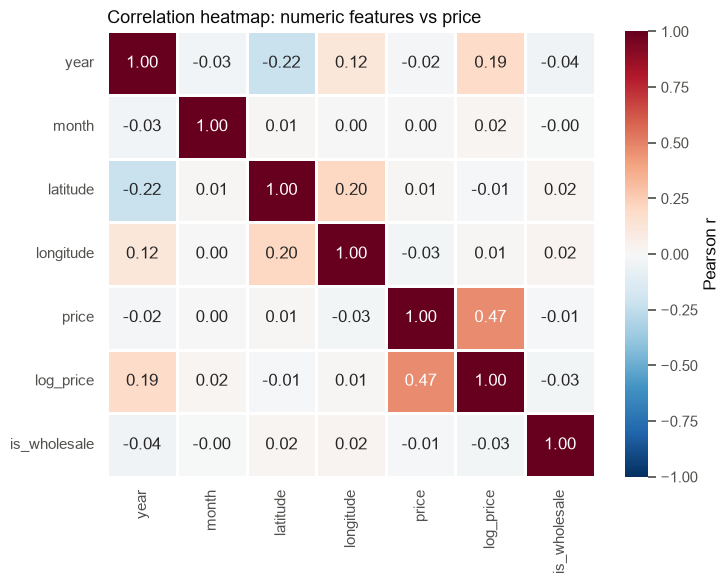

In [8]:
num_for_corr = ["year", "month", "latitude", "longitude", "price", "log_price"]
corr_df = df[num_for_corr].assign(is_wholesale=(df["pricetype"] == "Wholesale").astype(int))
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation heatmap: numeric features vs price", loc="left", fontsize=13)
plt.tight_layout()
plt.show()

**What it shows:** the numeric features (`year`, `month`, `latitude`, `longitude`) all have only weak linear correlations with price; `year` is the strongest (prices rise with inflation), and the log of price correlates more clearly than the raw price. `latitude`/`longitude` are correlated with each other because they both encode location.

**Decision:** numeric columns alone can't explain price, so the model must rely on the **categorical** features (above all `commodity`), which we one-hot encode. We keep `year` (trend) and `month` (seasonality) as numeric inputs and model the **log of price**, which has a clearer linear relationship.

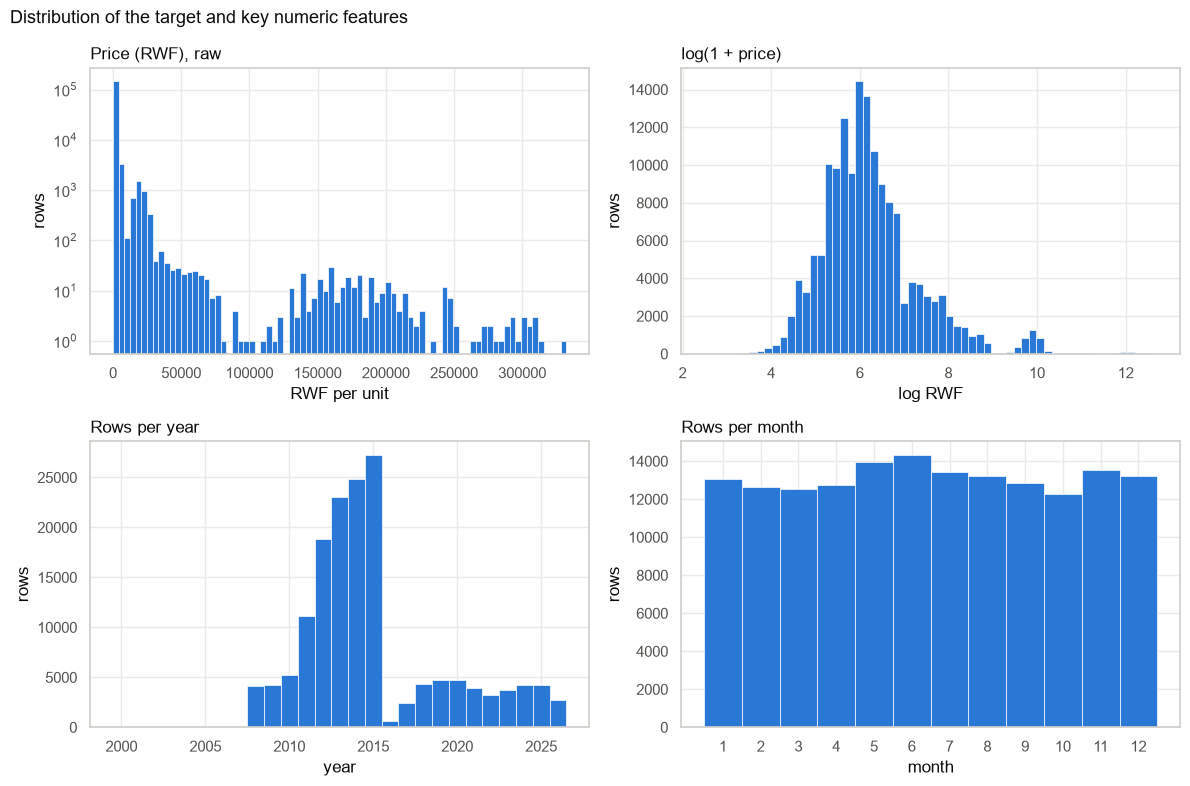

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(df["price"], bins=80, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0, 0].set(title="Price (RWF), raw", xlabel="RWF per unit", ylabel="rows", yscale="log")
axes[0, 1].hist(df["log_price"], bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0, 1].set(title="log(1 + price)", xlabel="log RWF", ylabel="rows")
axes[1, 0].hist(df["year"], bins=np.arange(df["year"].min(), df["year"].max() + 2) - 0.5,
                color=BLUE, edgecolor="white", linewidth=0.5)
axes[1, 0].set(title="Rows per year", xlabel="year", ylabel="rows")
axes[1, 1].hist(df["month"], bins=np.arange(0.5, 13.5), color=BLUE, edgecolor="white", linewidth=0.5)
axes[1, 1].set(title="Rows per month", xlabel="month", ylabel="rows", xticks=range(1, 13))
for a in axes.flat:
    a.title.set_position((0, 1)); a.title.set_ha("left")
fig.suptitle("Distribution of the target and key numeric features", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

**What it shows:** raw price is extremely right-skewed: most prices are a few hundred RWF, but a long tail (livestock, sacks, meat) reaches hundreds of thousands (note the log y-axis). After `log(1+price)` the distribution is compact and roughly bell-shaped. Most rows come from 2008–2015 (peak 2015, dip in 2016), with very few before 2008; months are evenly covered.

**Decision:** we train on **log(price)** with a `TransformedTargetRegressor` (`log1p` / `expm1`). Squared errors on raw RWF would be dominated by a few expensive items, and a linear model fits multiplicative effects (e.g. "Kigali is 10% more expensive") better in log space. The saved model still returns RWF. We **drop the years before 2008** (too few rows to learn a trend from).

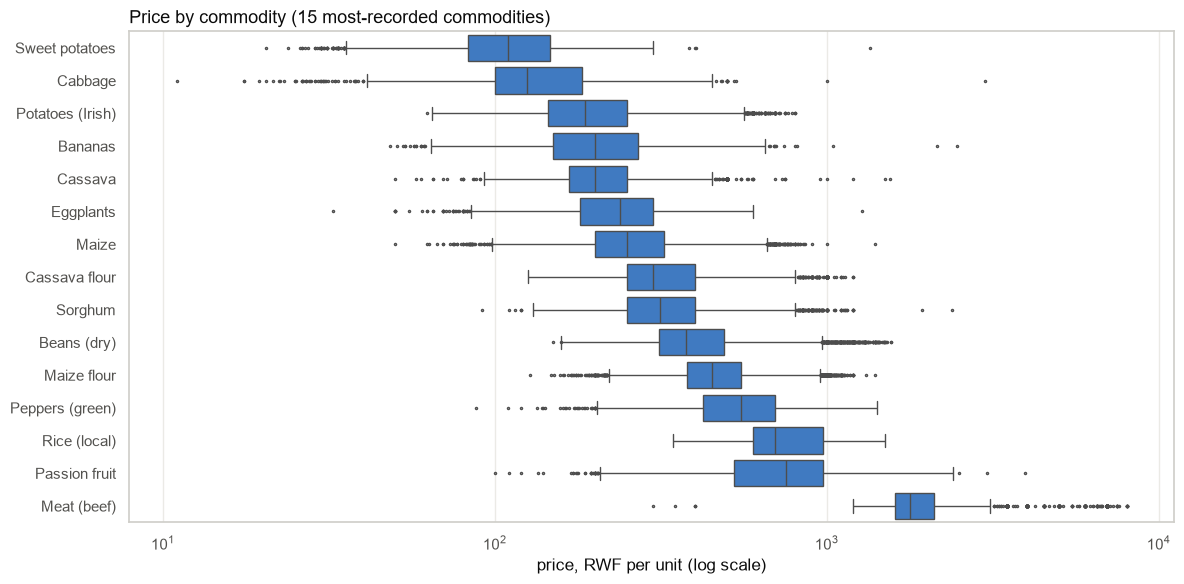

In [10]:
top_commodities = df["commodity"].value_counts().index[:15]
order = (df[df["commodity"].isin(top_commodities)].groupby("commodity")["price"].median()
         .sort_values().index)

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df[df["commodity"].isin(top_commodities)], x="price", y="commodity", order=order,
            color=BLUE, fliersize=1.5, linewidth=1, ax=ax, log_scale=True)
ax.set(xlabel="price, RWF per unit (log scale)", ylabel="")
ax.set_title("Price by commodity (15 most-recorded commodities)", loc="left", fontsize=13)
plt.tight_layout()
plt.show()

**What it shows:** the median price differs by **orders of magnitude** between commodities (e.g. a cheap vegetable vs. meat or oil), while the spread *within* a commodity is much smaller. Commodity is by far the strongest driver of price. Each box also has a few extreme points far outside the usual range.

**Decision:** `commodity` is the main input and is one-hot encoded. Because outliers must be judged **per commodity** (5,000 RWF is normal for meat but absurd for cabbage), we remove outliers with an IQR rule computed on log-price **within each commodity** (section 4).

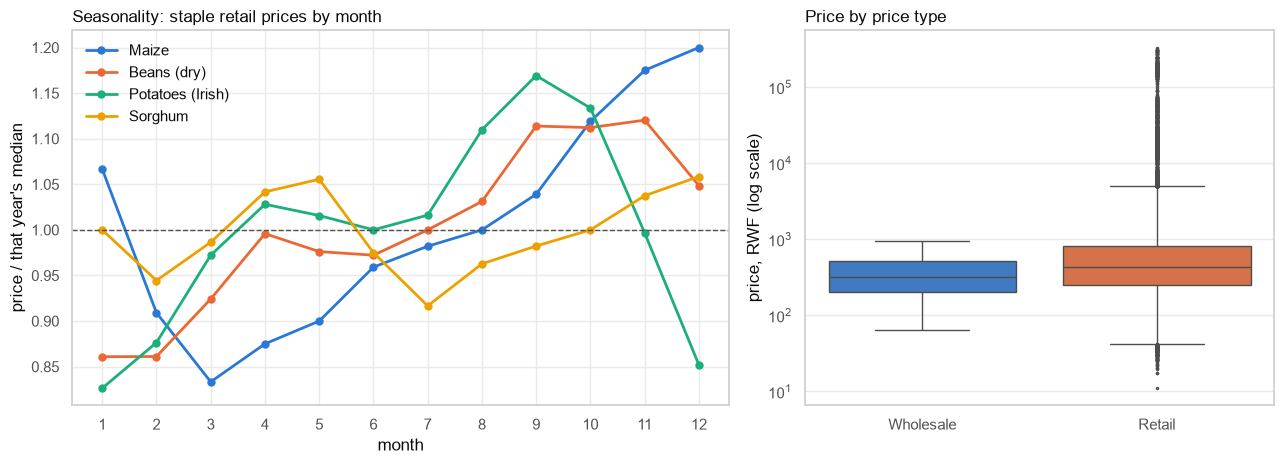

In [11]:
staples = ["Maize", "Beans (dry)", "Potatoes (Irish)", "Sorghum"]
staples = [s for s in staples if s in set(df.loc[df["pricetype"] == "Retail", "commodity"])]
season = (df[(df["commodity"].isin(staples)) & (df["pricetype"] == "Retail") & (df["year"] >= 2008)]
          .assign(rel=lambda d: d["price"] / d.groupby(["commodity", "year"])["price"].transform("median"))
          .groupby(["commodity", "month"])["rel"].median().unstack(0))

palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
for colour, s in zip(palette, staples):
    axes[0].plot(season.index, season[s], marker="o", markersize=5, linewidth=2, color=colour, label=s)
axes[0].axhline(1, color=MUTED, linewidth=1, linestyle="--")
axes[0].set(xlabel="month", ylabel="price / that year's median", xticks=range(1, 13))
axes[0].set_title("Seasonality: staple retail prices by month", loc="left")
axes[0].legend(frameon=False)

sns.boxplot(data=df, x="pricetype", y="price", hue="pricetype", palette=[BLUE, ORANGE], legend=False,
            fliersize=1.5, linewidth=1, log_scale=True, ax=axes[1])
axes[1].set(xlabel="", ylabel="price, RWF (log scale)")
axes[1].set_title("Price by price type", loc="left")
plt.tight_layout()
plt.show()

**What it shows:** staple prices follow Rwanda's **harvest cycle**: they are lowest right after the harvests (around Feb–Mar for Season A; potatoes again in Dec–Jan) and highest in the lean months (Sep–Dec), swinging by about ±15–20% around the yearly median. The right panel shows Wholesale prices are lower on average than Retail, but there are far fewer wholesale rows.

**Decision:** `month` is kept as an input so the model can learn seasonality (this is exactly what tells a farmer *when* to sell). `pricetype` is kept as an input, with a caveat that wholesale predictions are less reliable because of the small sample.

## 4. Feature engineering

### Columns dropped and why
| Column | Reason |
|---|---|
| `usdprice` | The target in another currency, so it **leaks** the answer |
| `currency` | Only one value (RWF), so it carries no information |
| `market_id`, `commodity_id` | ID codes that duplicate `market` / `commodity` |
| `date` | Replaced by `year` (trend/inflation) and `month` (seasonality) |
| `priceflag` | Describes how WFP computed the record (actual/aggregate); a farmer can't supply it |

### Features kept (11 model features: 4 numeric + 7 categorical)
- **Numeric:** `year`, `month`, `latitude`, `longitude`
- **Categorical:** `commodity`, `category`, `unit`, `market`, `admin1` (province), `admin2` (district), `pricetype`

### Farmer-friendly inputs (what the API/app asks for)
Only **5 inputs** are asked from the user: `commodity`, `market`, `pricetype`, `year`, `month`.
The other 6 model features are **looked up** automatically, because they are fully determined by the inputs:
- `market` → `latitude`, `longitude`, `admin1`, `admin2`
- `commodity` → `category`, `unit`

This avoids asking for inputs that duplicate each other (a farmer shouldn't type the GPS coordinates of a market they already chose) and makes inconsistent inputs (e.g. a market with someone else's coordinates) impossible. The lookup tables are saved with the model.

### Units
Each commodity has exactly one unit, so prices are already consistent per commodity (no conversion needed). `unit` is kept as a model feature and returned by the API so the price reads as e.g. "RWF/KG".

In [12]:
NUMERIC_FEATURES = ["year", "month", "latitude", "longitude"]
CATEGORICAL_FEATURES = ["commodity", "category", "unit", "market", "admin1", "admin2", "pricetype"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "price"

clean = df.drop(columns=["usdprice", "currency", "market_id", "commodity_id", "date", "priceflag"])

# Missing values: none in this download, but drop any rows with a missing feature/target to be safe
before = len(clean)
clean = clean.dropna(subset=FEATURES + [TARGET])
clean = clean[clean[TARGET] > 0]
print(f"Rows removed for missing/non-positive values: {before - len(clean)}")

# Sparse early years: too few rows to learn a trend from
before = len(clean)
clean = clean[clean["year"] >= 2008]
print(f"Rows removed from years < 2008: {before - len(clean)}")

# Outliers: IQR rule on log-price *within each commodity* (k = 3, so only extreme values go)
q1 = clean.groupby("commodity")["log_price"].transform(lambda s: s.quantile(0.25))
q3 = clean.groupby("commodity")["log_price"].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
is_outlier = (clean["log_price"] < q1 - 3 * iqr) | (clean["log_price"] > q3 + 3 * iqr)
print(f"Outliers removed (per-commodity IQR on log-price): {is_outlier.sum()} "
      f"({is_outlier.mean():.2%} of rows)")
clean = clean[~is_outlier].reset_index(drop=True)
print(f"\nClean dataset: {clean.shape[0]:,} rows")

Rows removed for missing/non-positive values: 0
Rows removed from years < 2008: 162


Outliers removed (per-commodity IQR on log-price): 298 (0.19% of rows)

Clean dataset: 157,333 rows


### Which features matter most?
Pearson correlation only works for numeric columns, so to compare **all** features we measure how much of the variance of log-price each feature explains on its own (R² of predicting log-price by that feature's group mean; for numeric features we group by each value).

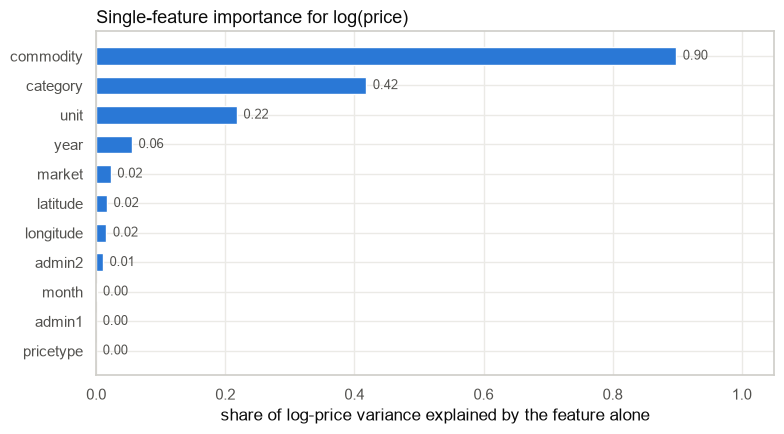

In [13]:
def variance_explained(frame, col, target="log_price"):
    group_mean = frame.groupby(col)[target].transform("mean")
    return r2_score(frame[target], group_mean)

importance = (pd.Series({c: variance_explained(clean, c) for c in FEATURES})
              .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
for i, v in enumerate(importance.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", color=MUTED, fontsize=9)
ax.set(xlabel="share of log-price variance explained by the feature alone", xlim=(0, 1.05))
ax.set_title("Single-feature importance for log(price)", loc="left", fontsize=13)
plt.tight_layout()
plt.show()

**What it shows:** `commodity` alone explains the large majority of the variance in log-price; `category` and `unit` also score highly, but only because they are coarser versions of commodity. Location (`market`, district, province, lat/lon), `year`, `pricetype` and `month` each explain a small share; they adjust the price *within* a commodity.

**Decision:** keep commodity as the core input and keep the location and time features to refine the price (where and when to sell). The location effect is small compared with commodity, but it's the part a farmer can act on.

### Hard-constraint check

In [14]:
n_rows, n_features = clean.shape[0], len(FEATURES)
print(f"Rows: {n_rows:,} (>= 1,000: {n_rows >= 1000})")
print(f"Feature columns: {n_features} (>= 8: {n_features >= 8})")
print(f"Numeric features ({len(NUMERIC_FEATURES)}): {NUMERIC_FEATURES}")
print(f"Categorical features ({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")
print(f"Target: '{TARGET}' (continuous, RWF), dtype {clean[TARGET].dtype}, "
      f"{clean[TARGET].nunique():,} distinct values, so this is a regression task")

Rows: 157,333 (>= 1,000: True)
Feature columns: 11 (>= 8: True)
Numeric features (4): ['year', 'month', 'latitude', 'longitude']
Categorical features (7): ['commodity', 'category', 'unit', 'market', 'admin1', 'admin2', 'pricetype']
Target: 'price' (continuous, RWF), dtype float64, 20,609 distinct values, so this is a regression task


## 5–6. Encoding, train/test split and scaling (Pipeline + ColumnTransformer)
Two preprocessing variants, both fitted **on the training set only** (inside `Pipeline.fit`), so no test information leaks into the scaler or encoders:

**Linear models (`SGDRegressor`, `LinearRegression`)**
- **Categoricals** → `OneHotEncoder(handle_unknown="ignore")`: one 0/1 column per category, because a linear model needs a separate weight per category (an unseen category becomes all zeros instead of crashing the API).
- **Numerics** → `StandardScaler`. Gradient descent (SGD) needs features on comparable scales, or it converges slowly or diverges.

**Tree models (`DecisionTreeRegressor`, `RandomForestRegressor`)**
- **Categoricals** → `OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)`: one integer code per category. Trees don't need one-hot: they split on thresholds and can isolate any category with a few splits, and they are not affected by feature scale, so numerics are passed through unscaled. This gives 11 dense columns instead of 226 sparse ones, which makes the forest **~60× faster to train** on one CPU core. That matters for retraining on the free Render server.

We split **first** (80/20, random, `random_state=42`). Every model is wrapped in a `Pipeline(preprocess → TransformedTargetRegressor(model, log1p/expm1))`, so the saved `.pkl` takes raw inputs and returns RWF.

In [15]:
X = clean[FEATURES]
y = clean[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])

def make_tree_preprocessor():
    return ColumnTransformer([
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL_FEATURES),
    ])

def make_pipeline(regressor, tree=False):
    return Pipeline([
        ("preprocess", make_tree_preprocessor() if tree else make_preprocessor()),
        ("model", TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)),
    ])

# Preprocessed matrices (fit on TRAIN only) for SGD tuning and the loss curve
pre = make_preprocessor().fit(X_train)
Xtr_t, Xte_t = pre.transform(X_train), pre.transform(X_test)
ytr_log, yte_log = np.log1p(y_train.to_numpy()), np.log1p(y_test.to_numpy())
print(f"Encoded feature matrix: {Xtr_t.shape[1]} columns "
      f"({len(NUMERIC_FEATURES)} scaled numeric + {Xtr_t.shape[1] - len(NUMERIC_FEATURES)} one-hot)")
print("Scaler means learned from TRAIN only:",
      dict(zip(NUMERIC_FEATURES, pre.named_transformers_["num"].mean_.round(2))))

Train: 125,866 rows | Test: 31,467 rows


Encoded feature matrix: 226 columns (4 scaled numeric + 222 one-hot)
Scaler means learned from TRAIN only: {'year': np.float64(2014.94), 'month': np.float64(6.52), 'latitude': np.float64(-2.02), 'longitude': np.float64(29.87)}


## 7–8. Main model: `SGDRegressor`, with hyperparameter tuning
`SGDRegressor` is linear regression fitted by **stochastic gradient descent** on the squared-error loss. We tune:
- **`eta0`**: initial learning rate (step size). The schedule is `invscaling`, so the step shrinks over time.
- **`alpha`**: L2 regularization strength (penalty on large weights).
- **`max_iter`**: number of epochs (full passes over the training data); `tol=None` so it runs exactly that many.

Models are fitted on log-price; we report the **test MSE in log space** (what SGD optimizes) and the **test RMSE in RWF**.

In [16]:
def rwf_rmse(y_true_rwf, pred_log):
    return np.sqrt(mean_squared_error(y_true_rwf, np.expm1(np.clip(pred_log, 0, 15))))

rows = []
for eta0 in [0.0001, 0.001, 0.01, 0.1]:
    for alpha in [1e-6, 1e-4, 1e-2]:
        for epochs in [5, 20, 50]:
            sgd = SGDRegressor(eta0=eta0, alpha=alpha, max_iter=epochs, tol=None,
                               learning_rate="invscaling", random_state=RANDOM_STATE)
            sgd.fit(Xtr_t, ytr_log)
            rows.append({
                "eta0": eta0, "alpha": alpha, "epochs": epochs,
                "train_MSE_log": mean_squared_error(ytr_log, sgd.predict(Xtr_t)),
                "test_MSE_log": mean_squared_error(yte_log, sgd.predict(Xte_t)),
                "test_RMSE_RWF": rwf_rmse(y_test, sgd.predict(Xte_t)),
            })
tuning = pd.DataFrame(rows).sort_values("test_MSE_log").reset_index(drop=True)
best_sgd_params = tuning.loc[0, ["eta0", "alpha", "epochs"]].to_dict()
print("Best SGD params:", best_sgd_params)
tuning.head(10)

Best SGD params: {'eta0': 0.01, 'alpha': 1e-06, 'epochs': 50.0}


,eta0,alpha,epochs,train_MSE_log,test_MSE_log,test_RMSE_RWF
0,0.0100,1e-06,50,0.0771,0.0771,"2,381"
1,0.1000,1e-06,50,0.0774,0.0772,"2,175"
2,0.0100,1e-04,50,0.0773,0.0773,"3,038"
3,0.1000,1e-04,50,0.0776,0.0775,"2,758"
4,0.1000,1e-06,5,0.0779,0.0779,"2,308"
5,0.1000,1e-04,5,0.0781,0.0781,"2,716"
6,0.1000,1e-06,20,0.0781,0.0781,"2,203"
7,0.1000,1e-04,20,0.0782,0.0783,"2,743"
8,0.0100,1e-06,20,0.0784,0.0786,"4,725"
9,0.0100,1e-04,20,0.0789,0.0791,"5,177"


In [17]:
# Effect of each hyperparameter, holding the other two at their best value
b = best_sgd_params
effects = {
    "eta0 (alpha, epochs fixed at best)": tuning[(tuning.alpha == b["alpha"]) & (tuning.epochs == b["epochs"])].sort_values("eta0"),
    "alpha (eta0, epochs fixed at best)": tuning[(tuning.eta0 == b["eta0"]) & (tuning.epochs == b["epochs"])].sort_values("alpha"),
    "epochs (eta0, alpha fixed at best)": tuning[(tuning.eta0 == b["eta0"]) & (tuning.alpha == b["alpha"])].sort_values("epochs"),
}
for name, tbl in effects.items():
    print(f"\n--- {name} ---")
    print(tbl[["eta0", "alpha", "epochs", "train_MSE_log", "test_MSE_log", "test_RMSE_RWF"]].to_string(index=False))


--- eta0 (alpha, epochs fixed at best) ---
  eta0  alpha  epochs  train_MSE_log  test_MSE_log  test_RMSE_RWF
 1e-04  1e-06      50         0.5393        0.5468          9,743
0.0010  1e-06      50         0.1146        0.1194          9,042
0.0100  1e-06      50         0.0771        0.0771          2,381
0.1000  1e-06      50         0.0774        0.0772          2,175

--- alpha (eta0, epochs fixed at best) ---
  eta0  alpha  epochs  train_MSE_log  test_MSE_log  test_RMSE_RWF
0.0100  1e-06      50         0.0771        0.0771          2,381
0.0100  1e-04      50         0.0773        0.0773          3,038
0.0100 0.0100      50         0.2305        0.2373          9,523

--- epochs (eta0, alpha fixed at best) ---
  eta0  alpha  epochs  train_MSE_log  test_MSE_log  test_RMSE_RWF
0.0100  1e-06       5         0.0923        0.0948          8,435
0.0100  1e-06      20         0.0784        0.0786          4,725
0.0100  1e-06      50         0.0771        0.0771          2,381


**How each hyperparameter changed the loss** (test MSE on log-price):
- **Learning rate `eta0`**: `0.0001` → 0.547 and `0.001` → 0.119. The steps are too small, so after 50 epochs the weights are still far from the minimum (underfitting). `0.01` → **0.0771** (best); `0.1` → 0.0772 converges just as well but takes noisier steps, with no extra gain.
- **Regularization `alpha`**: `1e-6` → **0.0771**, `1e-4` → 0.0773, `1e-2` → 0.237. Strong L2 pushes the one-hot commodity weights toward zero, but those weights are exactly what sets the price, so the model underfits. Train and test MSE are almost equal, so there's no overfitting to regularize away and the smallest alpha wins.
- **Epochs**: 5 → 0.0948, 20 → 0.0786, 50 → **0.0771**. More passes help until the model converges, with diminishing returns after ~20.

**Best:** `eta0=0.01, alpha=1e-6, 50 epochs`. Train ≈ test MSE everywhere, so the linear model is limited by **bias**, not variance. Tuning can't push it below ≈0.077, which is the closed-form `LinearRegression` optimum (0.0766, see the comparison table).

## 9. Loss curve (SGD with `partial_fit`)
We train a fresh `SGDRegressor` with the best `eta0`/`alpha` one epoch at a time with `partial_fit` (reshuffling the training rows each epoch, like `fit` does), and record train and test MSE (log-price) after every epoch.

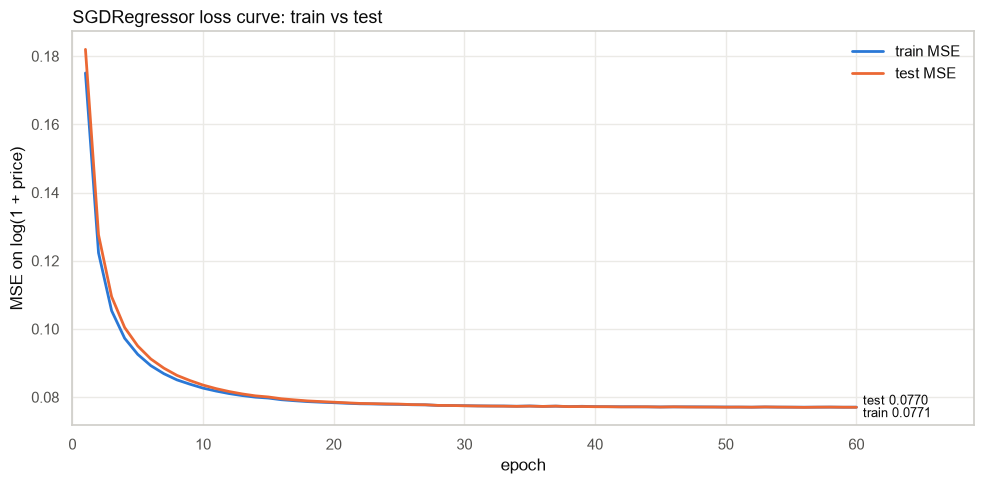

Epoch 1: train 0.1751 / test 0.1820 | Epoch 60: train 0.0771 / test 0.0770


In [18]:
N_EPOCHS = 60
curve_model = SGDRegressor(eta0=b["eta0"], alpha=b["alpha"], learning_rate="invscaling",
                           random_state=RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)
train_curve, test_curve = [], []
for epoch in range(N_EPOCHS):
    idx = rng.permutation(Xtr_t.shape[0])
    curve_model.partial_fit(Xtr_t[idx], ytr_log[idx])
    train_curve.append(mean_squared_error(ytr_log, curve_model.predict(Xtr_t)))
    test_curve.append(mean_squared_error(yte_log, curve_model.predict(Xte_t)))

epochs_axis = np.arange(1, N_EPOCHS + 1)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(epochs_axis, train_curve, color=BLUE, linewidth=2, label="train MSE")
ax.plot(epochs_axis, test_curve, color=ORANGE, linewidth=2, label="test MSE")
ax.text(N_EPOCHS + 0.5, train_curve[-1], f"train {train_curve[-1]:.4f}", color=INK, va="top", fontsize=9)
ax.text(N_EPOCHS + 0.5, test_curve[-1], f"test {test_curve[-1]:.4f}", color=INK, va="bottom", fontsize=9)
ax.set(xlabel="epoch", ylabel="MSE on log(1 + price)", xlim=(0, N_EPOCHS + 9))
ax.set_title("SGDRegressor loss curve: train vs test", loc="left", fontsize=13)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"Epoch 1: train {train_curve[0]:.4f} / test {test_curve[0]:.4f} | "
      f"Epoch {N_EPOCHS}: train {train_curve[-1]:.4f} / test {test_curve[-1]:.4f}")

**Reading the curve:** the loss falls steeply in the first ~10 epochs (test MSE 0.182 → ~0.084) and flattens after ~30 epochs at **≈0.077**. The test curve lies right on top of the train curve the whole time, so there is **no overfitting**. It is also no reason to train longer: the plateau equals the closed-form least-squares error, so SGD has converged and the remaining error comes from the linear model's limits (it can't represent commodity × market × year interactions).

## 10–11. Scatter plot before and after fitting a regression line
We pick the **numeric feature most correlated with the (log) target**, plot it against log-price, then fit a one-feature `LinearRegression` on the training set just for this plot.

|corr| with log(price):
year        0.1847
month       0.0185
longitude   0.0145
latitude    0.0104

Most correlated feature: year


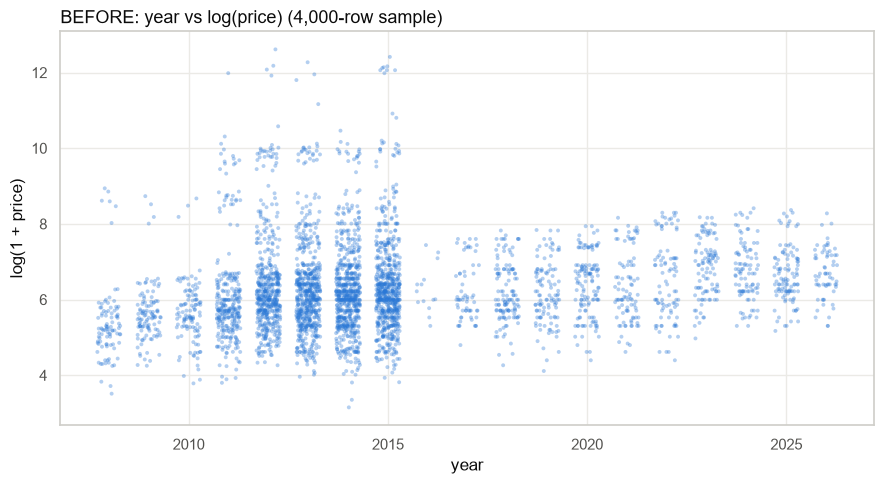

In [19]:
corr_with_target = clean[NUMERIC_FEATURES].corrwith(clean["log_price"]).abs().sort_values(ascending=False)
print("|corr| with log(price):")
print(corr_with_target.to_string())
best_feat = corr_with_target.index[0]
print(f"\nMost correlated feature: {best_feat}")

sample = clean.sample(4000, random_state=RANDOM_STATE)
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(sample)) if best_feat in ("year", "month") else 0

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sample[best_feat] + jitter, sample["log_price"], s=8, alpha=0.35, color=BLUE, edgecolors="none")
ax.set(xlabel=best_feat, ylabel="log(1 + price)")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.set_title(f"BEFORE: {best_feat} vs log(price) (4,000-row sample)", loc="left", fontsize=13)
plt.tight_layout()
plt.show()

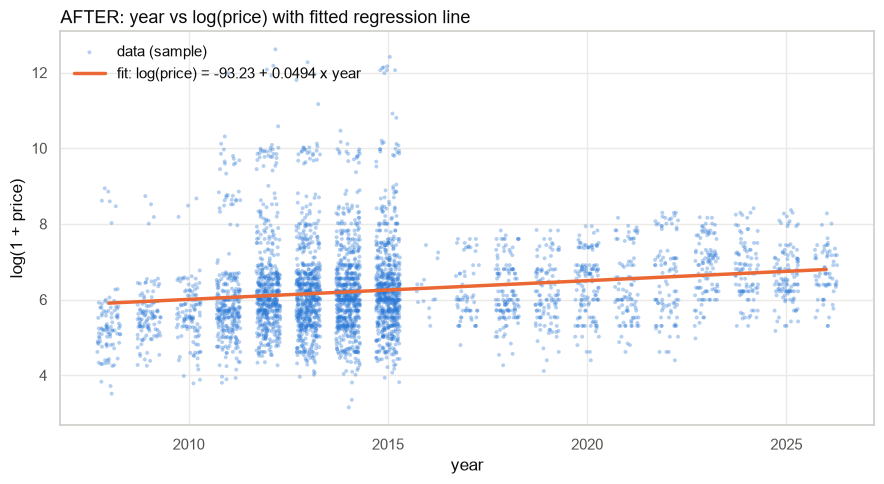

One-feature model test R^2 (log scale): 0.033; slope means about 5.1% change in price per +1 year


In [20]:
line_model = LinearRegression().fit(X_train[[best_feat]], np.log1p(y_train))
xs = np.linspace(clean[best_feat].min(), clean[best_feat].max(), 100)
ys = line_model.predict(pd.DataFrame({best_feat: xs}))

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sample[best_feat] + jitter, sample["log_price"], s=8, alpha=0.35, color=BLUE,
           edgecolors="none", label="data (sample)")
ax.plot(xs, ys, color=ORANGE, linewidth=2.5,
        label=f"fit: log(price) = {line_model.intercept_:.2f} + {line_model.coef_[0]:.4f} x {best_feat}")
ax.set(xlabel=best_feat, ylabel="log(1 + price)")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.set_title(f"AFTER: {best_feat} vs log(price) with fitted regression line", loc="left", fontsize=13)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()
r2_one = r2_score(np.log1p(y_test), line_model.predict(X_test[[best_feat]]))
print(f"One-feature model test R^2 (log scale): {r2_one:.3f}; slope means about "
      f"{np.expm1(line_model.coef_[0]):.1%} change in price per +1 {best_feat}")

**What it shows:** `year` is the numeric feature most correlated with log-price (|r| = 0.18; month and location are below 0.02). The fitted line has slope 0.049, i.e. prices rise by **about 5% per year** (inflation). But one feature explains only ~3% of the variance (test R² = 0.03): the huge vertical spread in every year comes from the *commodity*. This is why a **multivariate** model with the categorical features is needed.

## 7 & 12. Four models on the same test set, and the comparison table
All four use the same log-target wrapper and the same train/test split; linear models use one-hot + scaling, tree models use ordinal encoding (see section 5–6).
- `SGDRegressor`: best hyperparameters from the tuning above
- `LinearRegression`: closed-form least squares
- `DecisionTreeRegressor`: `min_samples_leaf=5` to avoid memorizing single rows
- `RandomForestRegressor`: 30 trees, `min_samples_leaf=3`, all 11 features considered at each split. With only 11 ordinal columns, sampling a subset of features (`max_features=0.7`) often hid the commodity column from a split and raised the test error, so all features are used. These settings keep the saved model under 30 MB and the retrain time to seconds on a single core, at about the same accuracy as a much larger forest.

MSE is computed on the **original RWF scale** (what the farmer sees). We also show RMSE in RWF (easier to read), test R² and the test MSE on log scale (relative error, not dominated by the few very expensive items).

In [21]:
models = {
    "SGDRegressor": SGDRegressor(eta0=b["eta0"], alpha=b["alpha"], max_iter=int(b["epochs"]), tol=None,
                                 learning_rate="invscaling", random_state=RANDOM_STATE),
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(min_samples_leaf=5, random_state=RANDOM_STATE),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=30, min_samples_leaf=3, max_features=1.0,
                                                   n_jobs=-1, random_state=RANDOM_STATE),
}
TREE_MODELS = {"DecisionTreeRegressor", "RandomForestRegressor"}
fitted, results = {}, []
for name, reg in models.items():
    pipe = make_pipeline(reg, tree=name in TREE_MODELS).fit(X_train, y_train)
    fitted[name] = pipe
    p_tr = np.clip(pipe.predict(X_train), 0, None)
    p_te = np.clip(pipe.predict(X_test), 0, None)
    results.append({
        "model": name,
        "train_MSE": mean_squared_error(y_train, p_tr),
        "test_MSE": mean_squared_error(y_test, p_te),
        "train_RMSE_RWF": np.sqrt(mean_squared_error(y_train, p_tr)),
        "test_RMSE_RWF": np.sqrt(mean_squared_error(y_test, p_te)),
        "test_R2": r2_score(y_test, p_te),
        "test_MSE_log": mean_squared_error(np.log1p(y_test), np.log1p(p_te)),
    })
comparison = pd.DataFrame(results).set_index("model").sort_values("test_MSE")
best_name = comparison.index[0]
print(f"Best model (lowest test MSE): {best_name}")
comparison

Best model (lowest test MSE): RandomForestRegressor


,train_MSE,test_MSE,train_RMSE_RWF,test_RMSE_RWF,test_R2,test_MSE_log
model,,,,,,
RandomForestRegressor,"666,849","2,127,703",816.6079,"1,459",0.9786,0.0177
DecisionTreeRegressor,"783,763","2,346,901",885.3040,"1,532",0.9763,0.0236
LinearRegression,"5,713,300","4,616,870","2,390","2,149",0.9535,0.0766
SGDRegressor,"6,472,726","5,671,515","2,544","2,381",0.9428,0.0771


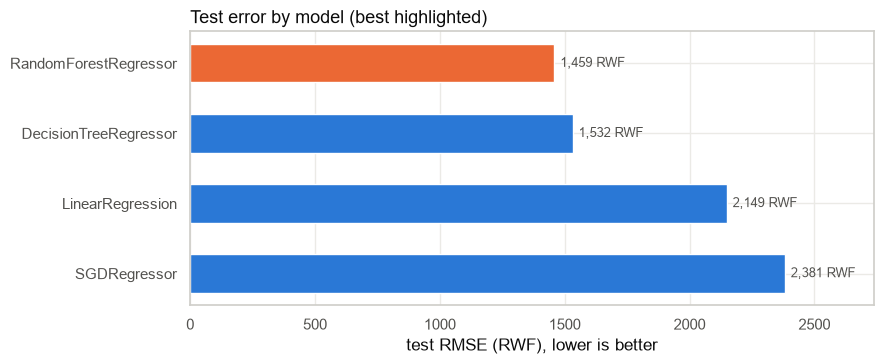

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order_m = comparison.sort_values("test_RMSE_RWF", ascending=False)
bars = ax.barh(order_m.index, order_m["test_RMSE_RWF"], color=[ORANGE if m == best_name else BLUE for m in order_m.index], height=0.55)
for bar, v in zip(bars, order_m["test_RMSE_RWF"]):
    ax.text(v + order_m["test_RMSE_RWF"].max() * 0.01, bar.get_y() + bar.get_height() / 2, f"{v:,.0f} RWF",
            va="center", color=MUTED, fontsize=9)
ax.set(xlabel="test RMSE (RWF), lower is better", xlim=(0, order_m["test_RMSE_RWF"].max() * 1.15))
ax.set_title("Test error by model (best highlighted)", loc="left", fontsize=13)
plt.tight_layout()
plt.show()

### Best model: `RandomForestRegressor` (lowest test MSE)
| model | test MSE (RWF²) | test RMSE (RWF) | test R² | test MSE (log) |
|---|---|---|---|---|
| **RandomForestRegressor** | **2,127,703** | **1,459** | **0.979** | **0.0177** |
| DecisionTreeRegressor | 2,346,901 | 1,532 | 0.976 | 0.0236 |
| LinearRegression | 4,616,870 | 2,149 | 0.953 | 0.0766 |
| SGDRegressor | 5,671,515 | 2,381 | 0.943 | 0.0771 |

**How the dataset affected each model**
- **Linear models (SGD, LinearRegression)** learn one additive weight per commodity, market, year step, etc. But in this dataset the effects **interact**: each commodity has its own inflation trend and its own regional price differences (meat in Kigali vs. a rural market, potato prices near the growing areas). A linear model has to use the same adjustment for every commodity, so it **underfits** (train and test log-MSE are both ≈0.077). Their train MSE in RWF is even *higher* than their test MSE because RWF-scale MSE is dominated by a handful of extreme, expensive-item outliers (the largest single train error is ~173,000 RWF; just 10 rows make up 63% of the test squared error), and the random split happened to leave the biggest misses in the training set. On the log scale train and test errors are equal, so this does not mean the models do better on unseen data. SGD reaches almost the closed-form solution; it is slightly worse in RWF because rare one-hot columns (rarely-recorded commodities and markets) get few gradient updates.
- **DecisionTreeRegressor** splits on commodity first and then on market/year, so it captures these interactions (log-MSE 0.024, 3× better). But a single tree is **high-variance**: train RMSE 885 vs. test 1,532 RWF.
- **RandomForestRegressor** averages 30 trees, each trained on a different bootstrap sample of the rows. This keeps the interactions and **reduces the variance**, giving the lowest test MSE (and the best R² and log-MSE). Some train/test gap remains (817 vs. 1,459 RWF), but its test error is the best.

**Is the error acceptable?** A test RMSE of 1,459 RWF looks large next to a median price of ~440 RWF, but RMSE in RWF is dominated by the few very expensive items (livestock/sacks up to 300k RWF). The log-MSE of 0.0177 corresponds to a **typical relative error of ≈13–14%**, which is useful for setting an asking price. Wholesale predictions are less reliable (few rows).

**Consequence for the API:** the best model is not SGD, so `/retrain` will **refit** the Random Forest pipeline on the original training data plus the uploaded rows. Thanks to ordinal encoding this takes seconds on one CPU core.

## 13. Save the best model and the input metadata
- `../API/best_model.pkl`: the **full Pipeline** (scaler + one-hot encoder + log-target model), so the API passes raw values and gets RWF back.
- `../API/model_metadata.json`: the 5 API inputs with their numeric ranges and allowed categorical values, plus the lookup tables (market → location, commodity → category/unit) and the test metrics.
- `../API/training_data.csv`: the cleaned training data (model feature columns + `price`), used by `/retrain`. It replaces the raw CSV copy in `API/`.

In [23]:
API_DIR.mkdir(exist_ok=True)
best_model = fitted[best_name]
joblib.dump(best_model, API_DIR / "best_model.pkl", compress=3)

market_lookup = (clean.groupby("market")[["latitude", "longitude", "admin1", "admin2"]].first()
                 .sort_index().to_dict(orient="index"))
commodity_lookup = (clean.groupby("commodity")[["category", "unit"]].first()
                    .sort_index().to_dict(orient="index"))
metadata = {
    "target": "price",
    "target_unit": "RWF per commodity unit",
    "best_model": best_name,
    "api_inputs": ["commodity", "market", "pricetype", "year", "month"],
    "numeric_ranges": {
        "year": {"min": int(clean["year"].min()), "max": int(clean["year"].max())},
        "month": {"min": 1, "max": 12},
    },
    "allowed_values": {
        "commodity": sorted(clean["commodity"].unique()),
        "market": sorted(clean["market"].unique()),
        "pricetype": sorted(clean["pricetype"].unique()),
    },
    "model_features": {"numeric": NUMERIC_FEATURES, "categorical": CATEGORICAL_FEATURES},
    "lookups": {"market": market_lookup, "commodity": commodity_lookup},
    "test_metrics": {k: round(float(v), 4) for k, v in comparison.loc[best_name].items()},
    "best_sgd_params": {k: float(v) for k, v in b.items()},
}
with open(API_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

clean[FEATURES + [TARGET]].to_csv(API_DIR / "training_data.csv", index=False)

for name in ["best_model.pkl", "model_metadata.json", "training_data.csv"]:
    print(f"{name:22s} {(API_DIR / name).stat().st_size / 1e6:6.1f} MB")
print("\nAPI inputs:", metadata["api_inputs"])
print("Numeric ranges:", metadata["numeric_ranges"])
print("pricetype:", metadata["allowed_values"]["pricetype"])
print(f"commodity ({len(metadata['allowed_values']['commodity'])}):", metadata["allowed_values"]["commodity"][:8], "...")
print(f"market ({len(metadata['allowed_values']['market'])}):", metadata["allowed_values"]["market"][:8], "...")

best_model.pkl           28.1 MB
model_metadata.json       0.0 MB
training_data.csv        16.2 MB

API inputs: ['commodity', 'market', 'pricetype', 'year', 'month']
Numeric ranges: {'year': {'min': 2008, 'max': 2026}, 'month': {'min': 1, 'max': 12}}
pricetype: ['Retail', 'Wholesale']
commodity (65): ['Apples (red)', 'Avocados', 'Bananas', 'Beans', 'Beans (dry)', 'Beans (fresh)', 'Beans (green, fresh)', 'Cabbage'] ...
market (109): ['Base', 'Batiment', 'Birambo', 'Bubare', 'Bugarama', 'Buhanda', 'Bumazi', 'Bushenge'] ...


## 14. Prediction function: `predict_one(row)`
Loads the saved model from disk (exactly what the API will do) and predicts the price for **one** row.

In [24]:
def predict_one(row, model_path=API_DIR / "best_model.pkl"):
    # Predict the price (RWF) for a single row (dict or pandas Series with the model features)
    model = joblib.load(model_path)
    frame = pd.DataFrame([dict(row)])[FEATURES]
    return float(model.predict(frame)[0])

test_row = X_test.iloc[0]
actual = y_test.iloc[0]
predicted = predict_one(test_row)
print(test_row.to_string())
print(f"\nPredicted: {predicted:,.0f} RWF/{test_row['unit']}")
print(f"Actual:    {actual:,.0f} RWF/{test_row['unit']}")
print(f"Error:     {predicted - actual:+,.0f} RWF ({(predicted - actual) / actual:+.1%})")

year                               2024
month                                 4
latitude                        -2.0700
longitude                       29.3500
commodity    Rice (imported, Tanzanian)
category             cereals and tubers
unit                                 KG
market                          Karongi
admin1                 Western Province
admin2                          Karongi
pricetype                        Retail

Predicted: 1,396 RWF/KG
Actual:    1,500 RWF/KG
Error:     -104 RWF (-6.9%)


In [25]:
# The same check on a few more test rows
sample_rows = X_test.sample(8, random_state=1)
check = sample_rows[["commodity", "market", "pricetype", "year", "month", "unit"]].copy()
check["actual_RWF"] = y_test.loc[sample_rows.index].round(0)
check["predicted_RWF"] = [round(predict_one(r)) for _, r in sample_rows.iterrows()]
check["error_%"] = ((check["predicted_RWF"] - check["actual_RWF"]) / check["actual_RWF"] * 100).round(1)
check

,commodity,market,pricetype,year,month,unit,actual_RWF,predicted_RWF,error_%
105726,Eggplants,Kimisagara,Retail,2015,7,KG,392.0000,399,1.8000
55726,Meat (beef),Matimba,Retail,2013,8,KG,"1,466",1488,1.5000
92561,Mangoes,Nkora,Retail,2015,1,KG,301.0000,305,1.3000
92915,Soybeans,Kayenzi,Retail,2015,1,KG,500.0000,439,-12.2000
28762,Eggplants,Nyabugogo,Retail,2012,3,KG,275.0000,272,-1.1000
87384,Tomatoes,Kibungo,Retail,2014,11,KG,354.0000,260,-26.6000
59033,Sweet potatoes,Kizi,Retail,2013,9,KG,96.0000,98,2.1000
84521,Charcoal,Mukarange,Retail,2014,9,Sack,"5,950",5725,-3.8000


### Summary
- The cleaned data meets every constraint (well over 1,000 rows, 11 features, numeric + categorical), and the target is log-transformed because of its extreme skew.
- Four scikit-learn models were trained in identical pipelines and compared on the same test set; the best one (see the table) is saved with its preprocessing to `API/best_model.pkl`, together with the input metadata the API and Flutter app will use.